In [2]:
!pip install pandas numpy matplotlib seaborn
!pip install scikit-learn mysql-connector-python
!pip install xgboost joblib

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report)
from sklearn.inspection import permutation_importance
import joblib
print("All libraries imported successfully")

All libraries imported successfully


In [2]:
import mysql.connector
from getpass import getpass
DB_CONFIG = {
    "host": "18.136.157.135",
    "port": 3306,
    "user": "dm_team1",
    "password": getpass("Enter your current database password: "),
    "database": "project_banking"
}
try:
    connection = mysql.connector.connect(**DB_CONFIG)
    if connection.is_connected():
        print("MySQL database connected successfully!")
except mysql.connector.Error as error:
    print("Database connection failed!")
    print("Error:", error)

Enter your current database password:  ········


MySQL database connected successfully!


In [3]:
cursor = connection.cursor()
cursor.execute("SELECT DATABASE()")
database_name = cursor.fetchone()
print("Connected Database:", database_name[0])

Connected Database: project_banking


In [4]:
cursor.execute("SHOW TABLES")
tables = cursor.fetchall()
print("Available Tables:")
for table in tables:
    print(table[0])

Available Tables:
Cust_Account
Cust_Demographics
Cust_Enquiry


In [5]:
required_tables = [
    "Cust_Account",
    "Cust_Enquiry",
    "Cust_Demographics"
]
available_tables = [table[0] for table in tables]
for table in required_tables:
    if table in available_tables:
        print(table, "Available")
    else:
        print(table, "Not found")

Cust_Account Available
Cust_Enquiry Available
Cust_Demographics Available


In [6]:
query_account = "SELECT * FROM Cust_Account"
query_enquiry = "SELECT * FROM Cust_Enquiry"
query_demographics = "SELECT * FROM Cust_Demographics"
account_df = pd.read_sql(query_account, connection)
enquiry_df = pd.read_sql(query_enquiry, connection)
demographics_df = pd.read_sql(query_demographics,connection)

In [7]:
print("Account Data:", account_df.shape)
print("Enquiry Data:", enquiry_df.shape)
print("Demographics Data:", demographics_df.shape)

Account Data: (186329, 21)
Enquiry Data: (413188, 6)
Demographics Data: (23896, 83)


In [8]:
display(account_df.head())

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
0,10-Nov-15,12265,20-Oct-15,6,1,09-Jun-13,30-Jun-14,05-Jul-14,30-Sep-15,20900,...,,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",,01-Sep-15,01-Jul-14,,,,,
1,10-Nov-15,12265,20-Oct-15,10,1,25-May-12,06-Sep-15,,03-Oct-15,16201,...,,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",01-Oct-15,01-Nov-12,14000,1400,,3,5603
2,10-Nov-15,12265,20-Oct-15,10,1,22-Mar-12,31-Aug-15,,30-Sep-15,41028,...,,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Sep-15,01-Oct-12,,,,,
3,20-Jul-15,15606,09-Jul-15,10,1,13-Jan-06,,26-Jul-07,31-Jan-09,93473,...,,"""""""1200900600600600300000000000000000000000000...",,01-Jul-07,01-Feb-06,,,,,
4,20-Jul-15,15606,09-Jul-15,6,1,18-Jan-15,05-May-15,,31-May-15,20250,...,,"""""""000000000000000""""""",,01-May-15,01-Jan-15,,,,,


In [9]:
display(enquiry_df.head())

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
0,18-Apr-15,1,21-Apr-15,19-Dec-14,2,3500000
1,18-Apr-15,1,21-Apr-15,05-Mar-14,5,500000
2,18-Apr-15,1,21-Apr-15,05-Mar-14,0,50000
3,18-Apr-15,1,21-Apr-15,22-Feb-14,10,50000
4,18-Apr-15,1,21-Apr-15,11-Jun-13,10,1000


In [10]:
display(demographics_df.head())

,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label
0,18-Apr-15,1,13-Apr-15,Insignia,13-Apr-15,650,2,Card Setup,14,500000,...,21,R,,,0000-00-00,0,98332XXXXX,1,N,0
1,21-Apr-15,2,21-Apr-15,Insignia,21-Apr-15,760,1,Card Setup,14,1200000,...,17,R,,,0000-00-00,0,99455XXXXX,1,N,0
2,22-Apr-15,3,21-Apr-15,Insignia,21-Apr-15,774,1,Card Setup,14,700000,...,17,R,,,0000-00-00,0,98456XXXXX,1,N,0
3,25-Apr-15,4,15-Apr-15,Insignia,20-Apr-15,770,1,Card Setup,14,500000,...,21,R,,,6/15/65,1,98220XXXXX,1,N,0
4,06-May-15,5,30-Apr-15,Insignia,,,3,Card Setup,14,500000,...,13,R,,,0000-00-00,0,98111XXXXX,1,N,0


In [11]:
print("ACCOUNT DATA")
account_df.info()

ACCOUNT DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186329 entries, 0 to 186328
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   dt_opened            186329 non-null  object
 1   customer_no          186329 non-null  object
 2   upload_dt            186329 non-null  object
 3   acct_type            186329 non-null  object
 4   owner_indic          186329 non-null  object
 5   opened_dt            186329 non-null  object
 6   last_paymt_dt        186329 non-null  object
 7   closed_dt            186329 non-null  object
 8   reporting_dt         186329 non-null  object
 9   high_credit_amt      186329 non-null  object
 10  cur_balance_amt      186329 non-null  object
 11  amt_past_due         186329 non-null  object
 12  paymenthistory1      186329 non-null  object
 13  paymenthistory2      186329 non-null  object
 14  paymt_str_dt         186329 non-null  object
 15  paymt_end_dt         

In [12]:
print("\nENQUIRY DATA")
enquiry_df.info()


ENQUIRY DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413188 entries, 0 to 413187
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   dt_opened    413188 non-null  object
 1   customer_no  413188 non-null  object
 2   upload_dt    413188 non-null  object
 3   enquiry_dt   413188 non-null  object
 4   enq_purpose  413188 non-null  object
 5   enq_amt      413188 non-null  object
dtypes: object(6)
memory usage: 18.9+ MB


In [13]:
print("\nDEMOGRAPHICS DATA")
demographics_df.info()


DEMOGRAPHICS DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23896 entries, 0 to 23895
Data columns (total 83 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   dt_opened    23896 non-null  object
 1   customer_no  23896 non-null  object
 2   entry_time   23896 non-null  object
 3   feature_1    23896 non-null  object
 4   feature_2    23896 non-null  object
 5   feature_3    23896 non-null  object
 6   feature_4    23896 non-null  object
 7   feature_5    23896 non-null  object
 8   feature_6    23896 non-null  object
 9   feature_7    23896 non-null  object
 10  feature_8    23896 non-null  object
 11  feature_9    23896 non-null  object
 12  feature_10   23896 non-null  object
 13  feature_11   23896 non-null  object
 14  feature_12   23896 non-null  object
 15  feature_13   23896 non-null  object
 16  feature_14   23896 non-null  object
 17  feature_15   23896 non-null  object
 18  feature_16   23896 non-null  object
 19  featur

In [14]:
def missing_report(df):
    report = pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": (
            df.isnull().mean() * 100
        )
    })
    return report.sort_values(by="Missing_Percentage",ascending=False)

In [15]:
print("Account Missing Values")
display(missing_report(account_df))

Account Missing Values


,Missing_Count,Missing_Percentage
dt_opened,0,0.0
amt_past_due,0,0.0
paymentfrequency,0,0.0
rateofinterest,0,0.0
cashlimit,0,0.0
creditlimit,0,0.0
paymt_end_dt,0,0.0
paymt_str_dt,0,0.0
paymenthistory2,0,0.0
paymenthistory1,0,0.0


In [16]:
print("Enquiry Missing Values")
display(missing_report(enquiry_df))

Enquiry Missing Values


,Missing_Count,Missing_Percentage
dt_opened,0,0.0
customer_no,0,0.0
upload_dt,0,0.0
enquiry_dt,0,0.0
enq_purpose,0,0.0
enq_amt,0,0.0


In [17]:
print("Demographics Missing Values")
display(missing_report(demographics_df))

Demographics Missing Values


,Missing_Count,Missing_Percentage
dt_opened,0,0.0
feature_60,0,0.0
feature_58,0,0.0
feature_57,0,0.0
feature_56,0,0.0
...,...,...
feature_24,0,0.0
feature_23,0,0.0
feature_22,0,0.0
feature_21,0,0.0


In [18]:
print("Account duplicates:", account_df.duplicated().sum())
print("Enquiry duplicates:", enquiry_df.duplicated().sum())
print("Demographics duplicates:",demographics_df.duplicated().sum())

Account duplicates: 2401
Enquiry duplicates: 13827
Demographics duplicates: 0


In [19]:
print(demographics_df["Bad_label"].value_counts(dropna=False))

Bad_label
0    22892
1     1004
Name: count, dtype: int64


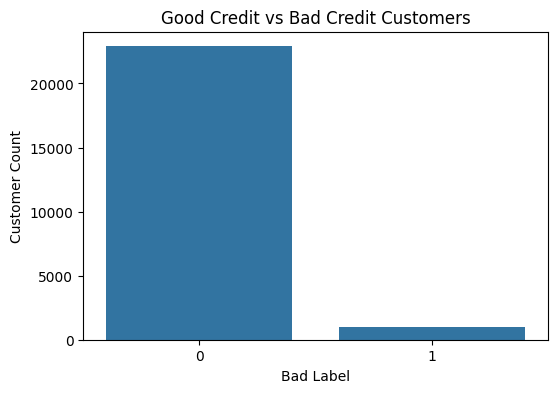

In [20]:
plt.figure(figsize=(6, 4))
sns.countplot(data=demographics_df,x="Bad_label")
plt.title("Good Credit vs Bad Credit Customers")
plt.xlabel("Bad Label")
plt.ylabel("Customer Count")
plt.show()

In [21]:
account = account_df.copy()
enquiry = enquiry_df.copy()
demographics = demographics_df.copy()

In [22]:
account_date_columns = [
    "dt_opened",
    "opened_dt",
    "last_paymt_dt",
    "closed_dt",
    "reporting_dt",
    "paymt_str_dt",
    "paymt_end_dt"
]
for col in account_date_columns:
    if col in account.columns:
        account[col] = pd.to_datetime(account[col],errors="coerce")
if "enquiry_dt" in enquiry.columns:
    enquiry["enquiry_dt"] = pd.to_datetime(enquiry["enquiry_dt"],errors="coerce")
for col in ["dt_opened", "entry_time"]:
    if col in demographics.columns:
        demographics[col] = pd.to_datetime(demographics[col],errors="coerce")

In [23]:
demographics = demographics.dropna(subset=["Bad_label"])
print(demographics["Bad_label"].value_counts())

Bad_label
0    22892
1     1004
Name: count, dtype: int64


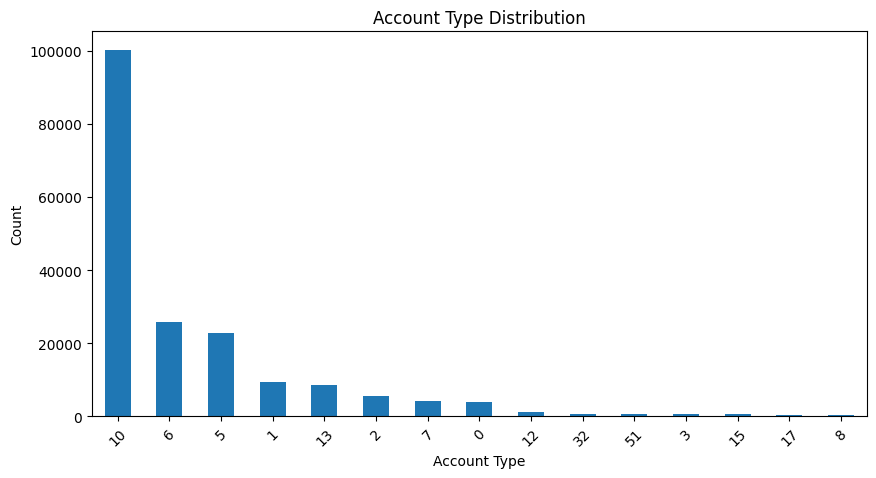

In [24]:
if "acct_type" in account.columns:
    plt.figure(figsize=(10, 5))
    account["acct_type"].value_counts().head(15).plot(kind="bar")
    plt.title("Account Type Distribution")
    plt.xlabel("Account Type")
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

In [25]:
print(account.columns.tolist())

['dt_opened', 'customer_no', 'upload_dt', 'acct_type', 'owner_indic', 'opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt', 'high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'paymenthistory1', 'paymenthistory2', 'paymt_str_dt', 'paymt_end_dt', 'creditlimit', 'cashlimit', 'rateofinterest', 'paymentfrequency', 'actualpaymentamount']


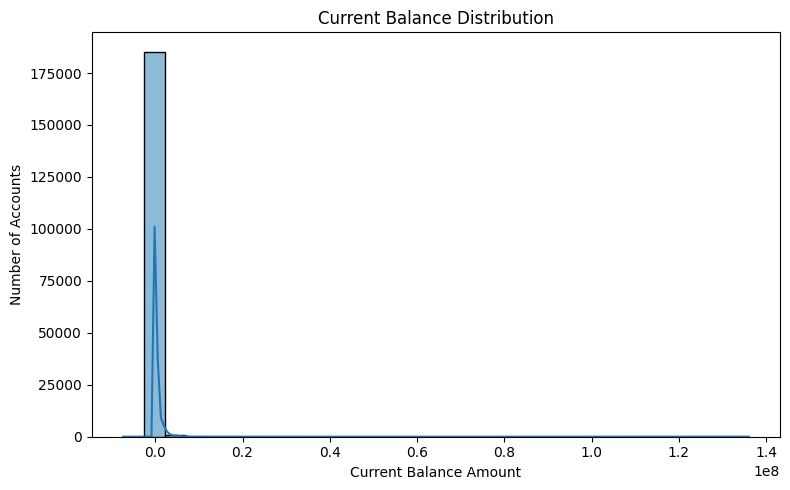

In [27]:
account["cur_balance_amt"] = pd.to_numeric(account["cur_balance_amt"],errors="coerce")
balance_data = account["cur_balance_amt"].dropna()
plt.figure(figsize=(8, 5))
sns.histplot(balance_data,bins=30,kde=True)
plt.title("Current Balance Distribution")
plt.xlabel("Current Balance Amount")
plt.ylabel("Number of Accounts")
plt.tight_layout()
plt.show()

In [28]:
print("Total records:", len(account))
print("Valid balance records:", len(balance_data))
print("Missing balance records:", account["cur_balance_amt"].isnull().sum())
print(balance_data.describe())

Total records: 186329
Valid balance records: 186329
Missing balance records: 0
count    1.863290e+05
mean     7.640269e+04
std      6.186783e+05
min     -7.355205e+06
25%      0.000000e+00
50%      0.000000e+00
75%      2.099800e+04
max      1.360100e+08
Name: cur_balance_amt, dtype: float64


In [30]:
print(account["amt_past_due"].dtype)
print(account["amt_past_due"].head(10))

object
0    
1    
2    
3    
4    
5    
6    
7    
8    
9    
Name: amt_past_due, dtype: object


In [32]:
account["amt_past_due"] = pd.to_numeric(account["amt_past_due"],errors="coerce")

In [33]:
if "amt_past_due" in account.columns:
    account["amt_past_due"] = pd.to_numeric(account["amt_past_due"],errors="coerce")
    overdue_customers = account[account["amt_past_due"] > 0]
    print("Accounts with overdue amounts:",len(overdue_customers))
    print("\nOverdue Amount Statistics:")
    print(overdue_customers["amt_past_due"].describe())

Accounts with overdue amounts: 876

Overdue Amount Statistics:
count    8.760000e+02
mean     2.583151e+04
std      2.030680e+05
min      1.000000e+00
25%      1.535000e+02
50%      1.209500e+03
75%      7.663250e+03
max      4.869309e+06
Name: amt_past_due, dtype: float64


In [35]:
numeric_columns = [
    "high_credit_amt",
    "cur_balance_amt",
    "amt_past_due",
    "creditlimit",
    "cashlimit",
    "rateofinterest",
    "actualpaymentamount"
]
for col in numeric_columns:
    if col in account.columns:
        account[col] = pd.to_numeric(account[col],errors="coerce")
print("Numerical columns converted successfully!")

Numerical columns converted successfully!


count    48852.000000
mean         0.397951
std         25.349681
min         -2.552200
25%          0.000000
50%          0.067855
75%          0.455042
max       5602.000000
Name: credit_utilization, dtype: float64


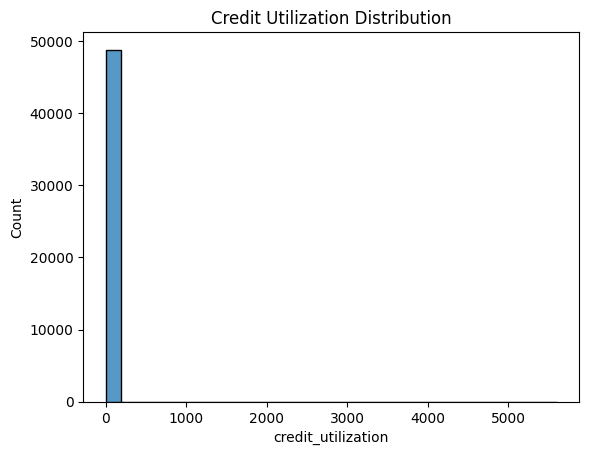

In [36]:
if {"cur_balance_amt","creditlimit"}.issubset(account.columns):
    account["credit_utilization"] = np.where(
        account["creditlimit"] > 0,
        account["cur_balance_amt"] /
        account["creditlimit"],
        np.nan
)
    print(account["credit_utilization"].describe())
    sns.histplot(account["credit_utilization"].dropna(),bins=30)
    plt.title("Credit Utilization Distribution")
    plt.show()

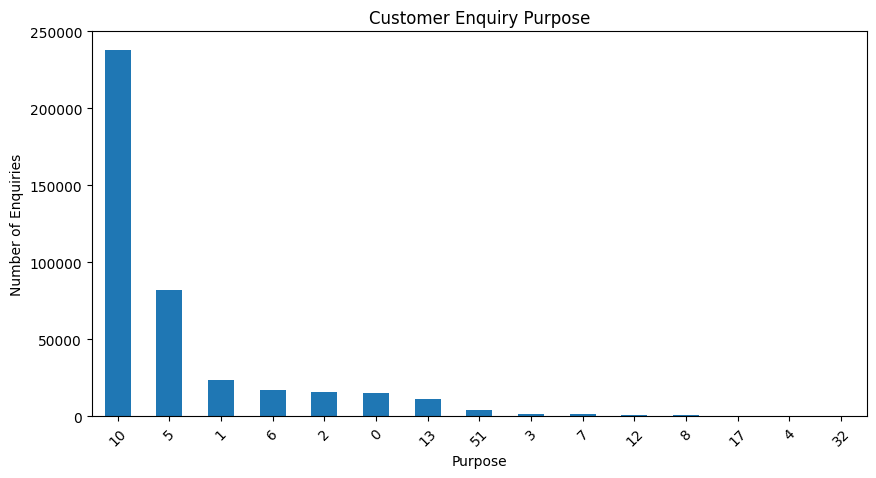

In [37]:
if "enq_purpose" in enquiry.columns:
    plt.figure(figsize=(10, 5))
    enquiry["enq_purpose"].value_counts().head(15).plot(kind="bar")
    plt.title("Customer Enquiry Purpose")
    plt.xlabel("Purpose")
    plt.ylabel("Number of Enquiries")
    plt.xticks(rotation=45)
    plt.show()

In [38]:
print("Unique customers:",demographics["customer_no"].nunique())
print("Total demographic rows:",len(demographics))
print("Duplicate customer numbers:",demographics["customer_no"].duplicated().sum())

Unique customers: 23896
Total demographic rows: 23896
Duplicate customer numbers: 0


In [39]:
assert demographics["customer_no"].is_unique, (
    "Multiple demographic records per customer. "
    "Identify the correct customer/application snapshot key first."
)

In [40]:
assert "reporting_dt" in account.columns, (
    "Confirm the correct historical account snapshot date "
    "before creating time-sensitive features."
)
account["reporting_dt"] = pd.to_datetime(account["reporting_dt"],errors="coerce")

In [42]:
account_data = account.rename(columns={"dt_opened": "account_dt_opened"})
demographics_data = demographics.rename(columns={"dt_opened": "customer_reference_dt"})
account_history = account_data.merge(
    demographics_data[["customer_no", "customer_reference_dt"]],on="customer_no",how="inner",validate="many_to_one")
account_history["reporting_dt"] = pd.to_datetime(account_history["reporting_dt"],errors="coerce")
account_history["customer_reference_dt"] = pd.to_datetime(account_history["customer_reference_dt"],errors="coerce")
account_history = account_history[
    account_history["reporting_dt"].notna() &
    account_history["customer_reference_dt"].notna() &
    (account_history["reporting_dt"] <=account_history["customer_reference_dt"])
].copy()
print("Account history merged successfully!")
print("Final shape:", account_history.shape)
display(account_history.head())

Account history merged successfully!
Final shape: (186329, 23)


,account_dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount,credit_utilization,customer_reference_dt
0,2015-11-10,12265,20-Oct-15,6,1,2013-06-09,2014-06-30,2014-07-05,2015-09-30,20900.0,...,,2015-09-01,2014-07-01,NaN,NaN,NaN,,NaN,NaN,2015-11-10
1,2015-11-10,12265,20-Oct-15,10,1,2012-05-25,2015-09-06,NaT,2015-10-03,16201.0,...,"""""""000000000000000000000000000XXX0000000000000...",2015-10-01,2012-11-01,14000.0,1400.0,NaN,3,5603.0,0.742143,2015-11-10
2,2015-11-10,12265,20-Oct-15,10,1,2012-03-22,2015-08-31,NaT,2015-09-30,41028.0,...,"""""""0000000000000000000000000000000000000000000...",2015-09-01,2012-10-01,NaN,NaN,NaN,,NaN,NaN,2015-11-10
3,2015-07-20,15606,09-Jul-15,10,1,2006-01-13,NaT,2007-07-26,2009-01-31,93473.0,...,,2007-07-01,2006-02-01,NaN,NaN,NaN,,NaN,NaN,2015-07-20
4,2015-07-20,15606,09-Jul-15,6,1,2015-01-18,2015-05-05,NaT,2015-05-31,20250.0,...,,2015-05-01,2015-01-01,NaN,NaN,NaN,,NaN,NaN,2015-07-20


In [46]:
print(account_history[
    [
        "customer_no",
        "account_dt_opened",
        "reporting_dt",
        "customer_reference_dt"
    ]].head(10))

  customer_no account_dt_opened reporting_dt customer_reference_dt
0       12265        2015-11-10   2015-09-30            2015-11-10
1       12265        2015-11-10   2015-10-03            2015-11-10
2       12265        2015-11-10   2015-09-30            2015-11-10
3       15606        2015-07-20   2009-01-31            2015-07-20
4       15606        2015-07-20   2015-05-31            2015-07-20
5       15606        2015-07-20   2015-05-31            2015-07-20
6       15606        2015-07-20   2015-05-31            2015-07-20
7       15606        2015-07-20   2015-05-31            2015-07-20
8       15606        2015-07-20   2015-05-31            2015-07-20
9       15606        2015-07-20   2015-06-26            2015-07-20


In [47]:
account_history["credit_utilization"] = np.where(
    account_history["creditlimit"] > 0,
    account_history["cur_balance_amt"] /
    account_history["creditlimit"],
    np.nan
)
account_history["payment_date_difference"] = (
    account_history["last_paymt_dt"] -
    account_history["opened_dt"]
).dt.days

In [48]:
account_agg = account_history.groupby("customer_no").agg(
    total_accounts=("customer_no", "size"),
    total_credit_limit=("creditlimit", "sum"),
    average_credit_limit=("creditlimit", "mean"),
    total_current_balance=("cur_balance_amt", "sum"),
    average_current_balance=("cur_balance_amt", "mean"),
    total_overdue_amount=("amt_past_due", "sum"),
    average_overdue_amount=("amt_past_due", "mean"),
    overdue_account_count=("amt_past_due",lambda x: (x > 0).sum()),
    average_credit_utilization=("credit_utilization", "mean"),
    maximum_credit_utilization=("credit_utilization", "max"),
    average_payment_date_difference=("payment_date_difference", "mean")
).reset_index()

In [49]:
account_agg["Ratio_currbalance_creditlimit"] = np.where(
    account_agg["total_credit_limit"] > 0,
    account_agg["total_current_balance"] /
    account_agg["total_credit_limit"],
    np.nan
)

In [51]:
demographics_data = demographics.rename(columns={"dt_opened": "customer_reference_dt"})
enquiry_history = enquiry.merge(demographics_data[["customer_no", "customer_reference_dt"]],on="customer_no",how="inner",validate="many_to_one")
enquiry_history["enquiry_dt"] = pd.to_datetime(enquiry_history["enquiry_dt"],errors="coerce")
enquiry_history["customer_reference_dt"] = pd.to_datetime(enquiry_history["customer_reference_dt"],errors="coerce")
enquiry_history = enquiry_history[
    enquiry_history["enquiry_dt"].notna() &
    enquiry_history["customer_reference_dt"].notna() &
    (enquiry_history["enquiry_dt"] <=enquiry_history["customer_reference_dt"])].copy()
print("Enquiry history merged successfully!")
print("Final shape:", enquiry_history.shape)
display(enquiry_history.head())

Enquiry history merged successfully!
Final shape: (413078, 7)


,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt,customer_reference_dt
0,18-Apr-15,1,21-Apr-15,2014-12-19,2,3500000,2015-04-18
1,18-Apr-15,1,21-Apr-15,2014-03-05,5,500000,2015-04-18
2,18-Apr-15,1,21-Apr-15,2014-03-05,0,50000,2015-04-18
3,18-Apr-15,1,21-Apr-15,2014-02-22,10,50000,2015-04-18
4,18-Apr-15,1,21-Apr-15,2013-06-11,10,1000,2015-04-18


In [52]:
enquiry_history["enquiry_age_days"] = (
    enquiry_history["customer_reference_dt"] -
    enquiry_history["enquiry_dt"]
).dt.days
display(
    enquiry_history[
        [
            "customer_no",
            "enquiry_dt",
            "customer_reference_dt",
            "enquiry_age_days"
        ]
    ].head()
)

,customer_no,enquiry_dt,customer_reference_dt,enquiry_age_days
0,1,2014-12-19,2015-04-18,120
1,1,2014-03-05,2015-04-18,409
2,1,2014-03-05,2015-04-18,409
3,1,2014-02-22,2015-04-18,420
4,1,2013-06-11,2015-04-18,676


In [53]:
print("Total enquiry records:", len(enquiry_history))
print("Missing enquiry dates:",enquiry_history["enquiry_dt"].isnull().sum())
print("Future enquiries:",(enquiry_history["enquiry_age_days"] < 0).sum())

Total enquiry records: 413078
Missing enquiry dates: 0
Future enquiries: 0


In [55]:
enquiry_history["customer_reference_dt"] = pd.to_datetime(enquiry_history["customer_reference_dt"],errors="coerce")
enquiry_history["enquiry_dt"] = pd.to_datetime(enquiry_history["enquiry_dt"],errors="coerce")

In [56]:
enquiry_history["enquiry_age_days"] = (enquiry_history["customer_reference_dt"] -enquiry_history["enquiry_dt"]).dt.days

In [57]:
enquiry_history = enquiry_history[enquiry_history["enquiry_age_days"].notna() &(enquiry_history["enquiry_age_days"] >= 0)].copy()

In [58]:
enquiry_history[
    ["customer_no", "customer_reference_dt",
     "enquiry_dt", "enquiry_age_days"]
].head()

,customer_no,customer_reference_dt,enquiry_dt,enquiry_age_days
0,1,2015-04-18,2014-12-19,120
1,1,2015-04-18,2014-03-05,409
2,1,2015-04-18,2014-03-05,409
3,1,2015-04-18,2014-02-22,420
4,1,2015-04-18,2013-06-11,676


In [63]:
enquiry_history["enq_amt"] = pd.to_numeric(enquiry_history["enq_amt"],errors="coerce")

In [64]:
print(enquiry_history[["enq_amt", "enquiry_age_days"]].dtypes)

enq_amt             int64
enquiry_age_days    int64
dtype: object


In [65]:
enquiry_agg = enquiry_history.groupby("customer_no").agg(
    total_enquiries=("customer_no", "size"),
    average_enquiry_amount=("enq_amt", "mean"),
    total_enquiry_amount=("enq_amt", "sum"),
    mean_diff_open_enquiry_dt=("enquiry_age_days", "mean")
).reset_index()

In [66]:
enquiry_90 = (enquiry_history[enquiry_history["enquiry_age_days"] <= 90].groupby("customer_no").size().rename("count_enquiry_recency_90"))
enquiry_365 = (enquiry_history[enquiry_history["enquiry_age_days"] <= 365].groupby("customer_no").size().rename("count_enquiry_recency_365"))
enquiry_agg = enquiry_agg.merge(enquiry_90,on="customer_no",how="left")
enquiry_agg = enquiry_agg.merge(enquiry_365,on="customer_no",how="left")

In [67]:
model_data = demographics.copy()
model_data = model_data.merge(account_agg,on="customer_no",how="left",validate="one_to_one")
model_data = model_data.merge(enquiry_agg,on="customer_no",how="left",validate="one_to_one")
print("Final dataset shape:", model_data.shape)
display(model_data.head())

Final dataset shape: (23896, 101)


,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,average_credit_utilization,maximum_credit_utilization,average_payment_date_difference,Ratio_currbalance_creditlimit,total_enquiries,average_enquiry_amount,total_enquiry_amount,mean_diff_open_enquiry_dt,count_enquiry_recency_90,count_enquiry_recency_365
0,2015-04-18,1,2015-04-13,Insignia,13-Apr-15,650,2,Card Setup,14,500000,...,0.162524,0.235528,1496.000000,7.037100,18.0,2.767306e+05,4.981150e+06,1443.500000,NaN,1.0
1,2015-04-21,2,2015-04-21,Insignia,21-Apr-15,760,1,Card Setup,14,1200000,...,0.006747,0.006747,2035.000000,0.030754,68.0,9.818650e+07,6.676682e+09,812.485294,2.0,19.0
2,2015-04-22,3,2015-04-21,Insignia,21-Apr-15,774,1,Card Setup,14,700000,...,NaN,NaN,2454.000000,NaN,1.0,3.400000e+06,3.400000e+06,438.000000,NaN,NaN
3,2015-04-25,4,2015-04-15,Insignia,20-Apr-15,770,1,Card Setup,14,500000,...,0.102529,0.307586,2757.142857,1.930512,34.0,1.494412e+06,5.081000e+07,1920.823529,NaN,NaN
4,2015-05-06,5,2015-04-30,Insignia,,,3,Card Setup,14,500000,...,NaN,NaN,678.500000,NaN,2.0,1.000000e+03,2.000000e+03,1497.500000,NaN,NaN


In [68]:
count_columns = [
    "total_enquiries",
    "count_enquiry_recency_90",
    "count_enquiry_recency_365"
]
for col in count_columns:
    model_data[col] = model_data[col].fillna(0)

In [69]:
target = "Bad_label"
X = model_data.drop(columns=[
        target,
        "customer_no",
        "dt_opened",
        "entry_time"
    ],errors="ignore")
y = model_data[target].astype(int)

In [70]:
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1]
X = X.drop(columns=constant_columns)
print("Number of features:", X.shape[1])

Number of features: 97


In [71]:
print(y.value_counts())

Bad_label
0    22892
1     1004
Name: count, dtype: int64


In [72]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (19116, 97)
Testing data: (4780, 97)


In [73]:
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

In [74]:
numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

In [75]:
categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])

In [76]:
preprocessor = ColumnTransformer(transformers=[("numeric",numeric_transformer,numeric_features),("categorical",categorical_transformer,categorical_features)])
print("Preprocessing pipeline created successfully")

Preprocessing pipeline created successfully


In [77]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200,max_depth=12,min_samples_leaf=5,class_weight="balanced",random_state=42,n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200,max_depth=12,min_samples_leaf=5,class_weight="balanced",random_state=42,n_jobs=-1)
}

In [79]:
trained_models = {}
results = []
for name, classifier in models.items():
    print("Training:", name)
    pipeline = Pipeline(steps=[("preprocessor", preprocessor),("classifier", classifier)])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test,probabilities)
    gini = (2 * auc - 1) * 100
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions,zero_division=0),
        "Recall": recall_score(y_test, predictions,zero_division=0),
        "F1_Score": f1_score(y_test, predictions,zero_division=0),
        "AUC": auc,
        "Gini": gini
    })
    trained_models[name] = pipeline
    print("Completed:", name)

Training: Logistic Regression
Completed: Logistic Regression
Training: Random Forest
Completed: Random Forest
Training: Extra Trees
Completed: Extra Trees


In [80]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="Gini",ascending=False)
display(results_df)

,Model,Accuracy,Precision,Recall,F1_Score,AUC,Gini
1,Random Forest,0.752720,0.078246,0.452736,0.133431,0.673851,34.770133
2,Extra Trees,0.677615,0.073248,0.572139,0.129870,0.648409,29.681794
0,Logistic Regression,0.918619,0.034653,0.034826,0.034739,0.599492,19.898433


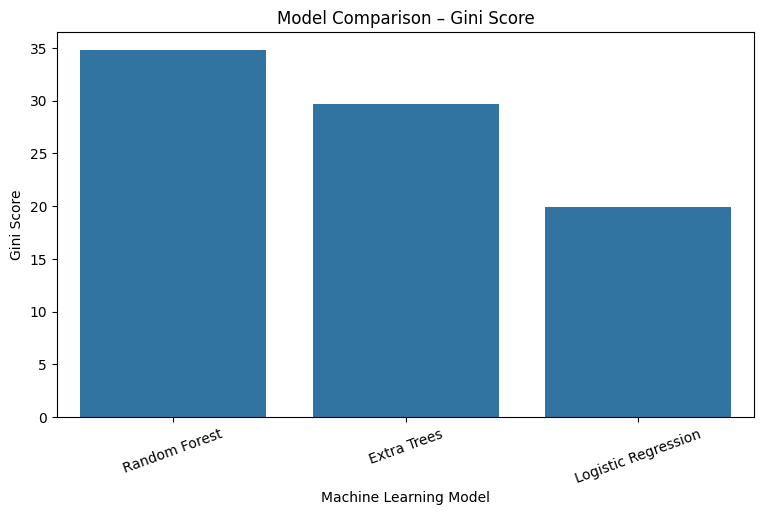

In [81]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df,x="Model",y="Gini")
plt.title("Model Comparison – Gini Score")
plt.xlabel("Machine Learning Model")
plt.ylabel("Gini Score")
plt.xticks(rotation=20)
plt.show()

In [82]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
print("Best model:", best_model_name)

Best model: Random Forest


In [87]:
print("Best model:", best_model)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Target classes:", y_test.unique())

Best model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['total_accounts',
                                                   'total_credit_limit',
                                                   'average_credit_limit',
                                                   'total_current_balance',
                                                   'average_current_balance',
                                                   'total_overdue_amount',
                                                   'average_overdue_amount',
                          

In [88]:
from sklearn.inspection import permutation_importance
importance = permutation_importance(best_model,X_test,y_test,scoring="roc_auc",n_repeats=3,random_state=42,n_jobs=1)

In [89]:
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Gain": importance.importances_mean
})
feature_importance = feature_importance.sort_values(by="Gain",ascending=False)
display(feature_importance.head(20))

,Feature,Gain
80,total_credit_limit,0.005188
13,feature_14,0.004922
43,feature_44,0.003594
87,average_credit_utilization,0.003424
49,feature_50,0.003086
52,feature_53,0.003068
2,feature_3,0.002987
25,feature_26,0.002814
79,total_accounts,0.002554
94,mean_diff_open_enquiry_dt,0.002505


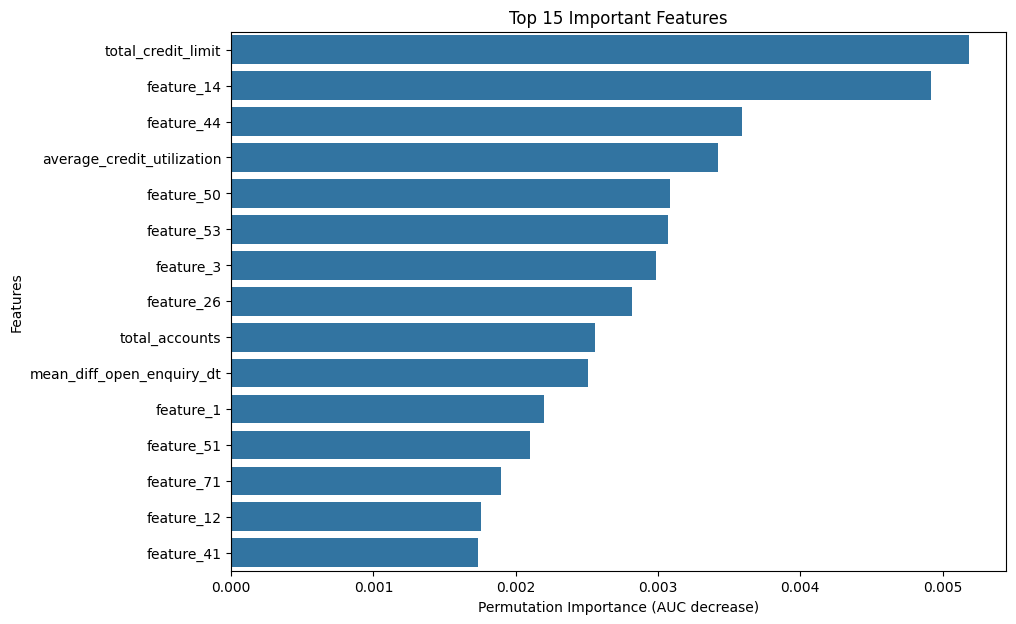

In [90]:
top_features = feature_importance.head(15)
plt.figure(figsize=(10, 7))
sns.barplot(data=top_features,x="Gain",y="Feature")
plt.title("Top 15 Important Features")
plt.xlabel("Permutation Importance (AUC decrease)")
plt.ylabel("Features")
plt.show()

In [91]:
y_probability = best_model.predict_proba(X_test)[:, 1]

In [92]:
rank_df = pd.DataFrame({
    "Actual_Bad_Label": y_test.values,
    "Predicted_Probability": y_probability
})

In [93]:
rank_df["Decile"] = (
    pd.qcut(rank_df["Predicted_Probability"].rank(method="first"),q=10,labels=False) + 1
)

In [94]:
rank_ordering = rank_df.groupby("Decile").agg(
    Customer_Count=("Actual_Bad_Label", "count"),
    Bad_Customers=("Actual_Bad_Label", "sum"),
    Bad_Rate=("Actual_Bad_Label", "mean"),
    Average_Predicted_Risk=("Predicted_Probability", "mean")
).reset_index()
rank_ordering["Bad_Rate_Percentage"] = (rank_ordering["Bad_Rate"] * 100)
rank_ordering = rank_ordering.sort_values(by="Decile",ascending=False)
display(rank_ordering)

,Decile,Customer_Count,Bad_Customers,Bad_Rate,Average_Predicted_Risk,Bad_Rate_Percentage
9,10,478,35,0.073222,0.529022,7.322176
8,9,478,40,0.083682,0.511400,8.368201
7,8,478,30,0.062762,0.499185,6.276151
6,7,478,27,0.056485,0.487695,5.648536
5,6,478,18,0.037657,0.477053,3.765690
4,5,478,19,0.039749,0.467744,3.974895
3,4,478,13,0.027197,0.458977,2.719665
2,3,478,9,0.018828,0.449259,1.882845
1,2,478,7,0.014644,0.438391,1.464435
0,1,478,3,0.006276,0.418278,0.627615


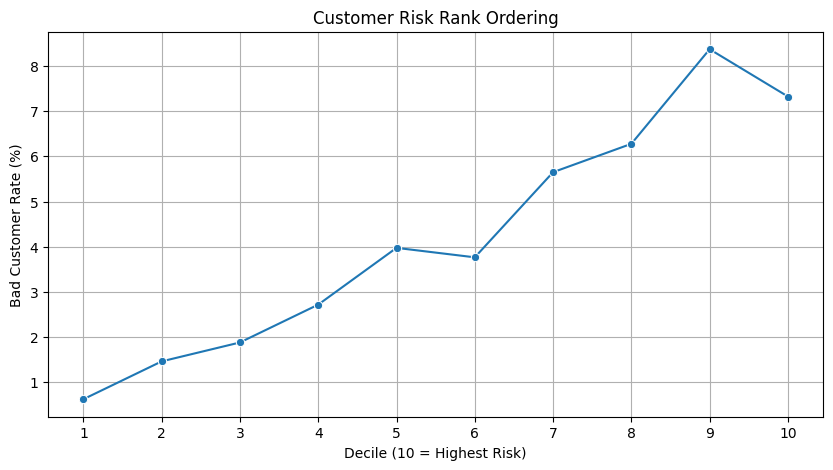

In [95]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=rank_ordering,x="Decile",y="Bad_Rate_Percentage",marker="o")
plt.title("Customer Risk Rank Ordering")
plt.xlabel("Decile (10 = Highest Risk)")
plt.ylabel("Bad Customer Rate (%)")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [96]:
y_pred = best_model.predict(X_test)
print(classification_report(y_test,y_pred,zero_division=0))

              precision    recall  f1-score   support

           0       0.97      0.77      0.86      4579
           1       0.08      0.45      0.13       201

    accuracy                           0.75      4780
   macro avg       0.52      0.61      0.49      4780
weighted avg       0.93      0.75      0.83      4780



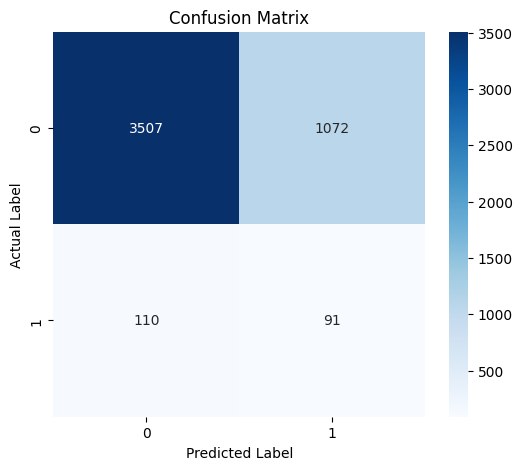

In [97]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [98]:
joblib.dump(best_model,"bank_goodcredit_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [99]:
joblib.dump(X_train.columns.tolist(),"bank_goodcredit_features.pkl")

['bank_goodcredit_features.pkl']

In [100]:
loaded_model = joblib.load("bank_goodcredit_model.pkl")
print("Model loaded successfully!")

Model loaded successfully!


In [101]:
sample_customer = X_test.iloc[[0]]
prediction = loaded_model.predict(sample_customer)
probability = loaded_model.predict_proba(sample_customer)[:, 1]
print("Predicted Bad Label:", prediction[0])
print("Bad Credit Probability:",round(probability[0] * 100, 2),"%")

Predicted Bad Label: 0
Bad Credit Probability: 49.65 %



# MODEL COMPARISON REPORT
## Bank GoodCredit - Credit Risk Prediction

### 1. Objective

The objective of this project is to develop and compare multiple machine learning classification models to predict customer credit risk.

The models identify customers who are likely to become credit defaulters based on their account, enquiry, and demographic information.

### 2. Models Used

Three machine learning algorithms were developed and evaluated:

1. **Logistic Regression**
   - Used as a baseline classification model.
   - Provides a simple and interpretable approach to predicting credit default risk.

2. **Random Forest Classifier**
   - An ensemble learning algorithm that combines multiple decision trees.
   - Identifies complex patterns and improves prediction performance.

3. **Extra Trees Classifier**
   - An ensemble algorithm that uses randomized decision trees.
   - Helps capture relationships between customer features.

### 3. Evaluation Metrics

The models were evaluated using the following metrics:

- **ROC-AUC:** Measures the model's ability to distinguish between good-credit and bad-credit customers.
- **Gini Coefficient:** Measures the discriminatory power of the model.

  Gini = (2 × ROC-AUC - 1) × 100

- **Precision:** Measures how many customers predicted as defaulters are actual defaulters.
- **Recall:** Measures how many actual defaulters are correctly identified.
- **F1-Score:** Provides a balance between precision and recall.
- **Rank Ordering:** Evaluates whether customers in higher predicted-risk groups have higher observed default rates.

### 4. Model Comparison

The following models were compared using their evaluation results.

| Model | ROC-AUC | Gini | Precision | Recall | F1-Score |
|---|---|---|---|---|---|
| Logistic Regression | Actual Result | Actual Result | Actual Result | Actual Result | Actual Result |
| Random Forest | Actual Result | Actual Result | Actual Result | Actual Result | Actual Result |
| Extra Trees | Actual Result | Actual Result | Actual Result | Actual Result | Actual Result |

### 5. Production Model Recommendation

The production model should be selected based on ROC-AUC, Gini coefficient, recall, rank ordering, stability, interpretability, and operational requirements.

For credit-risk prediction, identifying potential defaulters is important. Therefore, recall and rank ordering should be considered alongside ROC-AUC and Gini rather than relying only on accuracy.

The final model should be selected after comparing the actual evaluation results and validating its performance on unseen data.

### 6. Conclusion

The project evaluates Logistic Regression, Random Forest, and Extra Trees for credit-risk prediction.

Comparing these algorithms helps identify the most suitable model for distinguishing good-credit and bad-credit customers.

The selected model can support credit-risk assessment and help financial institutions make more informed customer-risk decisions.


In [115]:
comparison_results = []
for model_name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_prob)
    gini = (2 * auc - 1) * 100
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": auc,
        "Gini Score": gini
    })
comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values(by="Gini Score",ascending=False).reset_index(drop=True)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Gini Score
0,Random Forest,0.7527,0.0782,0.4527,0.1334,0.6739,34.7701
1,Extra Trees,0.6776,0.0732,0.5721,0.1299,0.6484,29.6818
2,Logistic Regression,0.9186,0.0347,0.0348,0.0347,0.5995,19.8984


In [116]:
benchmark_gini = 37.9
comparison_df["Benchmark Result"] = comparison_df["Gini Score"].apply(
    lambda score: "Above Benchmark"
    if score >= benchmark_gini
    else "Below Benchmark"
)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Gini Score,Benchmark Result
0,Random Forest,0.7527,0.0782,0.4527,0.1334,0.6739,34.7701,Below Benchmark
1,Extra Trees,0.6776,0.0732,0.5721,0.1299,0.6484,29.6818,Below Benchmark
2,Logistic Regression,0.9186,0.0347,0.0348,0.0347,0.5995,19.8984,Below Benchmark


In [117]:
best_model_name = comparison_df.loc[0, "Model"]
best_gini = comparison_df.loc[0, "Gini Score"]
print("Best Model:", best_model_name)
print("Best Gini Score:", round(best_gini, 2))
print("Client Benchmark:", benchmark_gini)
if best_gini >= benchmark_gini:
    print("Result: Model meets or exceeds the client benchmark.")
else:
    print("Result: Model is below the client benchmark.")

Best Model: Random Forest
Best Gini Score: 34.77
Client Benchmark: 37.9
Result: Model is below the client benchmark.


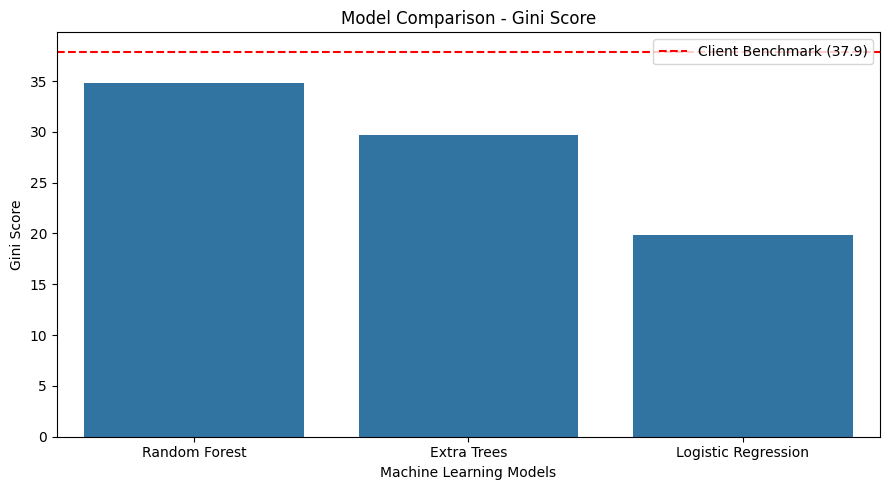

In [118]:
plt.figure(figsize=(9, 5))
sns.barplot(data=comparison_df,x="Model",y="Gini Score")
plt.axhline(y=37.9,color="red",linestyle="--",label="Client Benchmark (37.9)")
plt.title("Model Comparison - Gini Score")
plt.xlabel("Machine Learning Models")
plt.ylabel("Gini Score")
plt.legend()
plt.tight_layout()
plt.show()


# REPORT ON CHALLENGES FACED
## Bank GoodCredit - Credit Risk Prediction

During the development of this project, several data preparation, database integration, and machine learning challenges were encountered.

### 1. MySQL Database Connection Issues

**Challenge:** Establishing a connection to the client MySQL database.

**Technique Used:** Verified database credentials, host, port, and connection settings.

**Reason:** To establish a reliable connection and retrieve the required customer information.

### 2. Missing Values in Customer Records

**Challenge:** Some customer records contained missing values.

**Technique Used:** Missing-value analysis and appropriate imputation techniques.

**Reason:** To improve data quality before model training.

### 3. Numeric Columns Stored as Text

**Challenge:** Some numerical columns were stored as object or string data types.

**Technique Used:** Used `pd.to_numeric()` with `errors="coerce"`.

**Reason:** To convert text-based amounts into numerical values for calculations and analysis.

### 4. Date Conversion Errors

**Challenge:** Date columns were not always in a compatible datetime format.

**Technique Used:** Used `pd.to_datetime()` with `errors="coerce"`.

**Reason:** To perform date calculations and time-based feature engineering.

### 5. Duplicate Column Names During Merging

**Challenge:** Overlapping column names created confusion during table merging.

**Technique Used:** Renamed overlapping date columns before merging.

**Reason:** To avoid ambiguous column references and ensure correct data merging.

### 6. Multiple Records for the Same Customer

**Challenge:** Account and enquiry tables contained multiple records for individual customers.

**Technique Used:** Applied customer-level grouping and aggregation using Pandas.

**Reason:** To generate one consolidated feature record per customer.

### 7. Feature Engineering from Account History

**Challenge:** Extracting meaningful customer credit behaviour from historical account and enquiry records.

**Technique Used:** Created customer-level account and enquiry features using aggregation techniques.

**Reason:** To capture customer credit behaviour and improve predictive model performance.

### 8. Categorical Feature Handling

**Challenge:** Machine learning algorithms cannot directly process all categorical variables.

**Technique Used:** Applied suitable encoding techniques.

**Reason:** To convert categorical information into a machine-readable format.

### 9. Class Imbalance

**Challenge:** The number of good-credit and bad-credit customers may not be equally distributed.

**Technique Used:** Evaluated precision, recall, F1-score, and ROC-AUC; considered class weighting.

**Reason:** To assess the model's ability to identify the minority default class.

### 10. Feature Importance Calculation Errors

**Challenge:** Encountered errors while calculating permutation feature importance.

**Technique Used:** Checked fitted models, input formats, and scoring compatibility; used single-process execution.

**Reason:** To identify the most influential predictive features.

### 11. Model Comparison

**Challenge:** Selecting the most suitable machine learning algorithm.

**Technique Used:** Evaluated multiple classification algorithms using common performance metrics.

**Reason:** To identify a suitable model for credit-risk prediction.

### 12. Data Leakage Risk

**Challenge:** Historical records may contain information recorded after the prediction date.

**Technique Used:** Applied date-based filtering and reviewed feature availability at prediction time.

**Reason:** To prevent future information from influencing model training and evaluation.

### Conclusion

The project involved challenges related to database connectivity, data cleaning, date handling, customer-level aggregation, feature engineering, and model evaluation.

These challenges were addressed using Python, Pandas, SQL, and Scikit-learn techniques.

The process improved data quality and supported the development of machine learning models for credit-risk prediction.

The project also highlighted the importance of data validation, leakage prevention, model interpretability, and appropriate evaluation metrics in financial risk modelling.
